# EDA — Clasificación de Materiales Industriales

**Proyecto Final — Especialización Analítica y Ciencia de Datos**  
Universidad de Medellín

**Target:** `familia_cod` — 8 categorías de materiales industriales

## 0. Setup — Entorno Colab

In [3]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Entorno configurado correctamente")

Python: c:\Users\marianarada_mejorcdt\Desktop\PROYECTO FINAL\proyecto_final_clasificacion_materiales\.venv\Scripts\python.exe
Pandas: 3.1.0
NumPy: 2.4.6
Scikit-learn: 1.9.1
Entorno configurado correctamente


In [5]:
from pathlib import Path
import os
import subprocess

REPO = "proyecto_final_clasificacion_materiales"
REPO_URL = "https://github.com/marianarada/proyecto_final_clasificacion_materiales.git"

# Buscar la raíz del repositorio desde la ubicación actual
current_path = Path.cwd()
REPO_PATH = None

for path in [current_path, *current_path.parents]:
    if (path / ".git").exists():
        REPO_PATH = path
        break

# Si no encuentra el repositorio, comprobar si estamos en Google Colab
if REPO_PATH is None:
    colab_path = Path("/content") / REPO

    if Path("/content").exists():
        if not colab_path.exists():
            subprocess.run(
                ["git", "clone", REPO_URL],
                cwd="/content",
                check=True
            )
        REPO_PATH = colab_path
    else:
        raise FileNotFoundError(
            "No se encontró la raíz del repositorio. "
            "Verifica que estés ejecutando el notebook dentro del proyecto."
        )

# Establecer directorio de trabajo
os.chdir(REPO_PATH)

print("Working directory:", os.getcwd())
print("Repositorio encontrado correctamente.")


Working directory: c:\Users\marianarada_mejorcdt\Desktop\PROYECTO FINAL\proyecto_final_clasificacion_materiales
Repositorio encontrado correctamente.


In [6]:
# Instalar dependencias del proyecto
!pip install -e . -q

In [7]:
# Mover archivos Excel al path esperado por load_dataset()
os.makedirs('data/raw', exist_ok=True)
os.makedirs('../reports/figures', exist_ok=True)
!cp Data/*.xlsx data/raw/ 2>/dev/null || true
print('Archivos en data/raw/:', os.listdir('data/raw'))

Archivos en data/raw/: ['.gitkeep', 'Ariba_eventos_RFP.xlsx', 'Maestro_verdad_simulacion.xlsx', 'ME2M_historico_compras.xlsx']


El sistema no puede encontrar la ruta especificada.
"true" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


In [8]:
import sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.config_loader import load_config
from src.data.load_data import load_dataset
from src.data.validate import validate_dataset

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
PALETTE = sns.color_palette('tab10', 8)

NOMBRES = {
    'LUB': 'Lubricantes', 'INS': 'Instrumentación', 'TUV': 'Tubería/Válvulas',
    'EPP': 'EPP', 'ELE': 'Eléctricos', 'QUI': 'Químicos',
    'HER': 'Herramientas', 'MEC': 'Mecánicos'
}

print('Imports OK')

Imports OK


In [9]:
config = load_config()
df = load_dataset()
print(validate_dataset(df, config).summary())
print(f'Shape: {df.shape}')
df.head(3)

=== Validacion: OK ===
Shape: (2500, 13)


,material_id,familia_cod,categoria_cod,subcategoria_cod,texto_breve,texto_largo,marca,um,precio_usd,filas_me2m,items_ariba,grupo_sap,texto_completo
0,3000001,MEC,MEC-01,MEC-01-A,RODAM RIGIDO BOLAS 6308-2RS1 FAG,FAG RODAMIENTO RÍGDIO DE BOLAS 18257-WHW 6308-...,fag,un,67.86,11,0,10100.0,rodam rigido bolas 6308-2rs1 fag | fag rodamie...
1,3000002,MEC,MEC-01,MEC-01-A,RODAM BOLAS 6203-ZZ KOYO,Rodamiento de bolas 6203-ZZ 51x101x10 mm sella...,koyo,un,6.86,8,1,10100.0,rodam bolas 6203-zz koyo | rodamiento de bolas...
2,3000003,EPP,EPP-04,EPP-04-B,OVEROL IGNIFUGO TALLA M,OVEROL IGNÍFUGO TALLA M ALGODÓN AZUL 2 PIEZAS....,sin_marca,un,13.67,1,0,70400.0,overol ignifugo talla m | overol ignifugo tall...


## 1. Distribución del Target

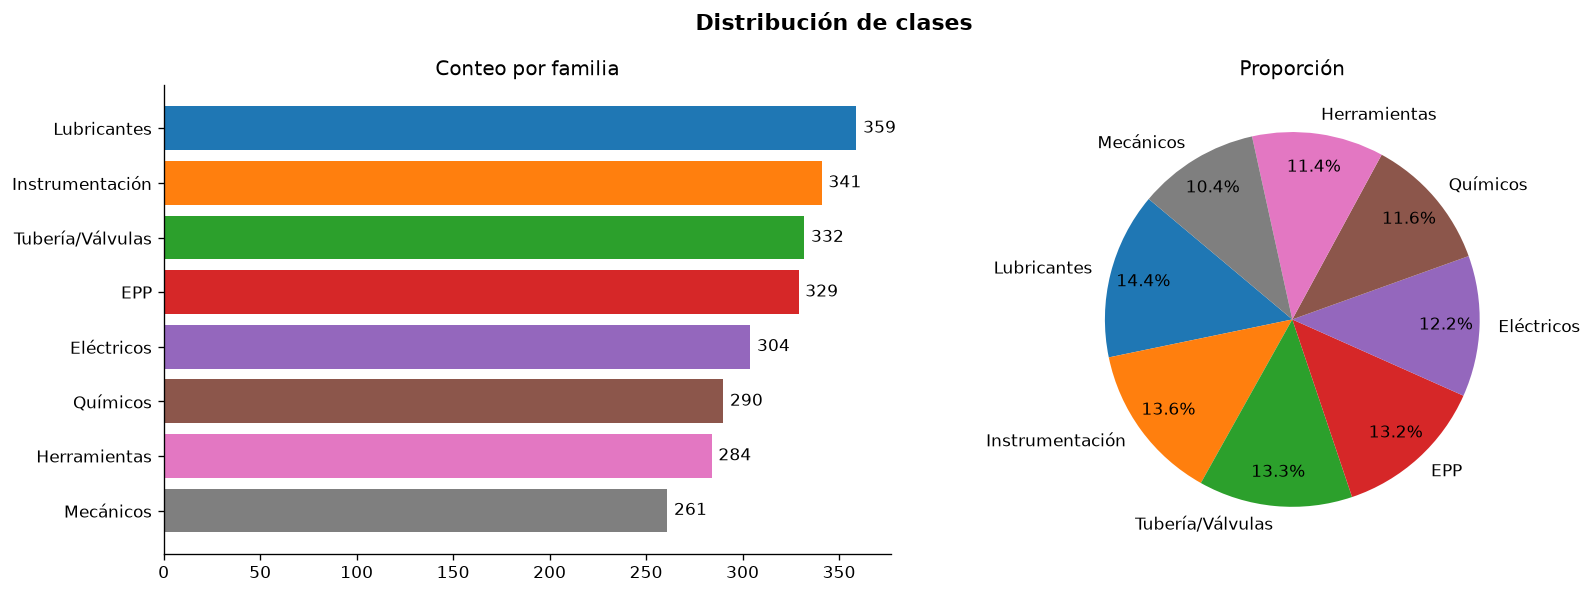

Imbalance ratio: 1.38x  → dataset casi perfectamente balanceado


In [10]:
counts = df['familia_cod'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars = axes[0].barh([NOMBRES[c] for c in counts.index], counts.values, color=PALETTE)
axes[0].bar_label(bars, fmt='%d', padding=4)
axes[0].set_title('Conteo por familia')
axes[0].invert_yaxis()

axes[1].pie(
    counts.values,
    labels=[NOMBRES[c] for c in counts.index],
    autopct='%1.1f%%', colors=PALETTE, startangle=140, pctdistance=0.82
)
axes[1].set_title('Proporción')

plt.suptitle('Distribución de clases', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/01_distribucion_clases.png', bbox_inches='tight')
plt.show()
print(f'Imbalance ratio: {counts.max()/counts.min():.2f}x  → dataset casi perfectamente balanceado')

## 2. Análisis de Texto

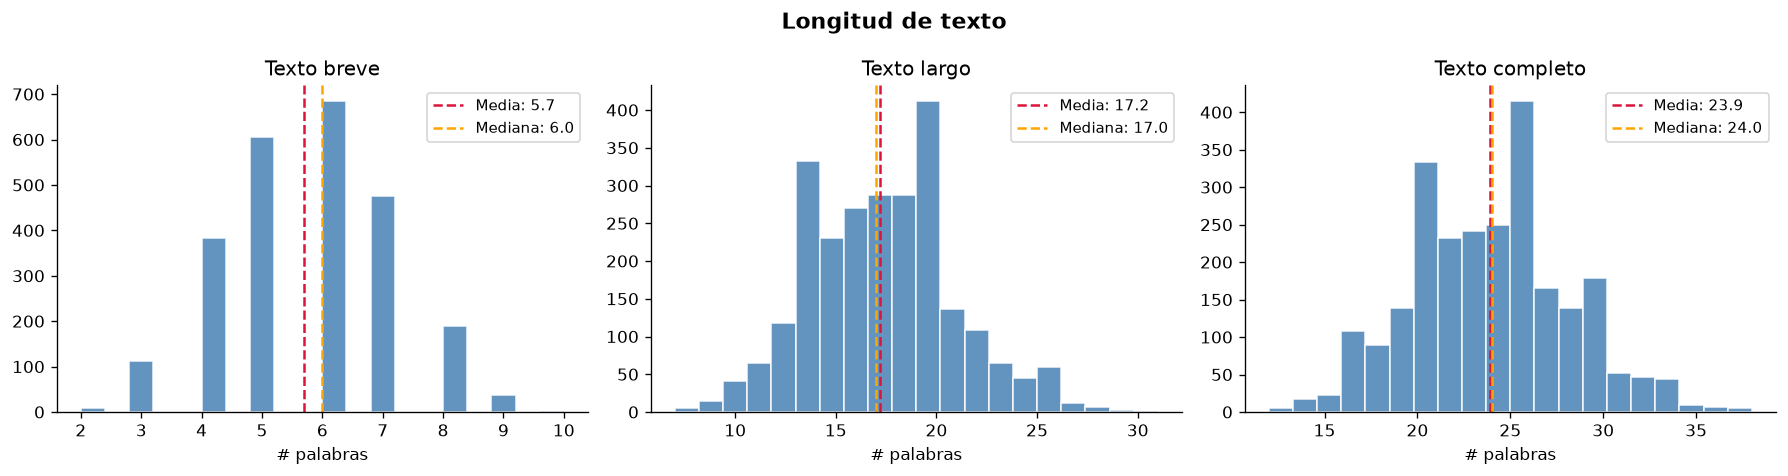

       n_breve  n_largo  n_total
count   2500.0   2500.0   2500.0
mean       5.7     17.2     23.9
std        1.4      3.6      4.2
min        2.0      7.0     12.0
25%        5.0     15.0     21.0
50%        6.0     17.0     24.0
75%        7.0     19.0     27.0
max       10.0     31.0     38.0


In [11]:
df['n_breve'] = df['texto_breve'].str.split().str.len()
df['n_largo'] = df['texto_largo'].str.split().str.len()
df['n_total'] = df['texto_completo'].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, t in zip(axes,
                      ['n_breve', 'n_largo', 'n_total'],
                      ['Texto breve', 'Texto largo', 'Texto completo']):
    ax.hist(df[col], bins=20, color='steelblue', edgecolor='white', alpha=0.85)
    ax.axvline(df[col].mean(),   color='crimson', ls='--', label=f'Media: {df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='orange',  ls='--', label=f'Mediana: {df[col].median():.1f}')
    ax.set_title(t)
    ax.set_xlabel('# palabras')
    ax.legend(fontsize=9)

plt.suptitle('Longitud de texto', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/02_longitud_texto.png', bbox_inches='tight')
plt.show()
print(df[['n_breve', 'n_largo', 'n_total']].describe().round(1))

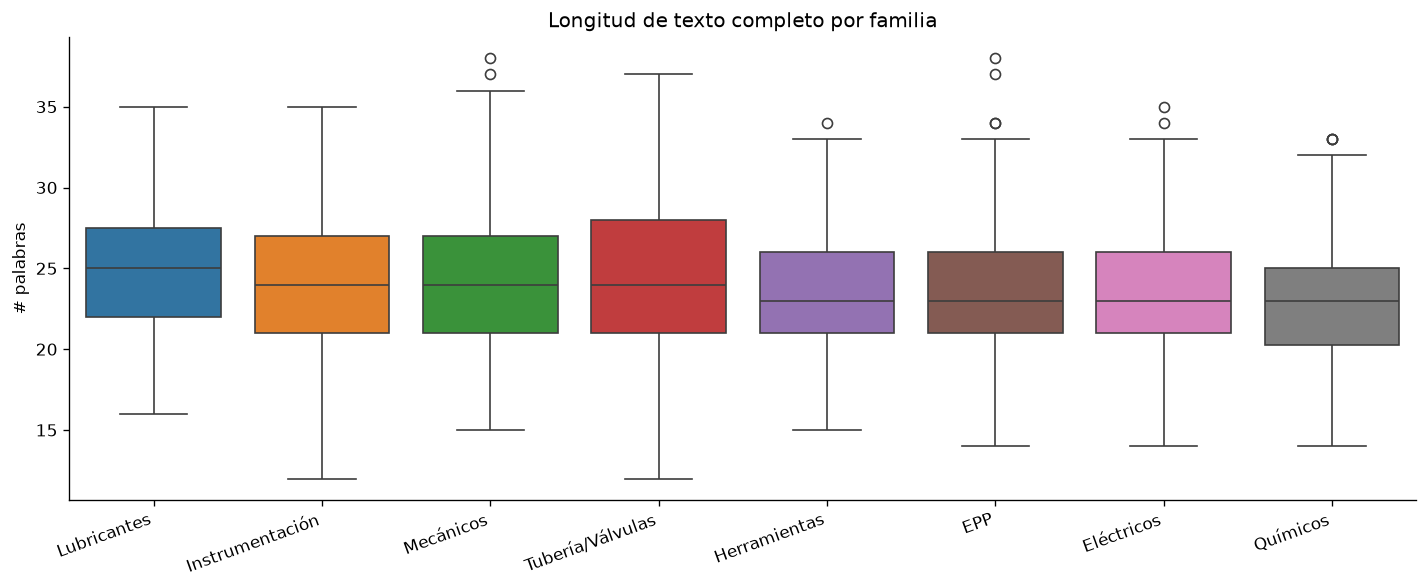

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
order = df.groupby('familia_cod')['n_total'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='familia_cod', y='n_total', order=order, palette='tab10', ax=ax)
ax.set_xticklabels([NOMBRES[c] for c in order], rotation=20, ha='right')
ax.set_title('Longitud de texto completo por familia')
ax.set_xlabel('')
ax.set_ylabel('# palabras')
plt.tight_layout()
plt.savefig('../reports/figures/03_texto_por_familia.png', bbox_inches='tight')
plt.show()

## 3. Features Categóricas

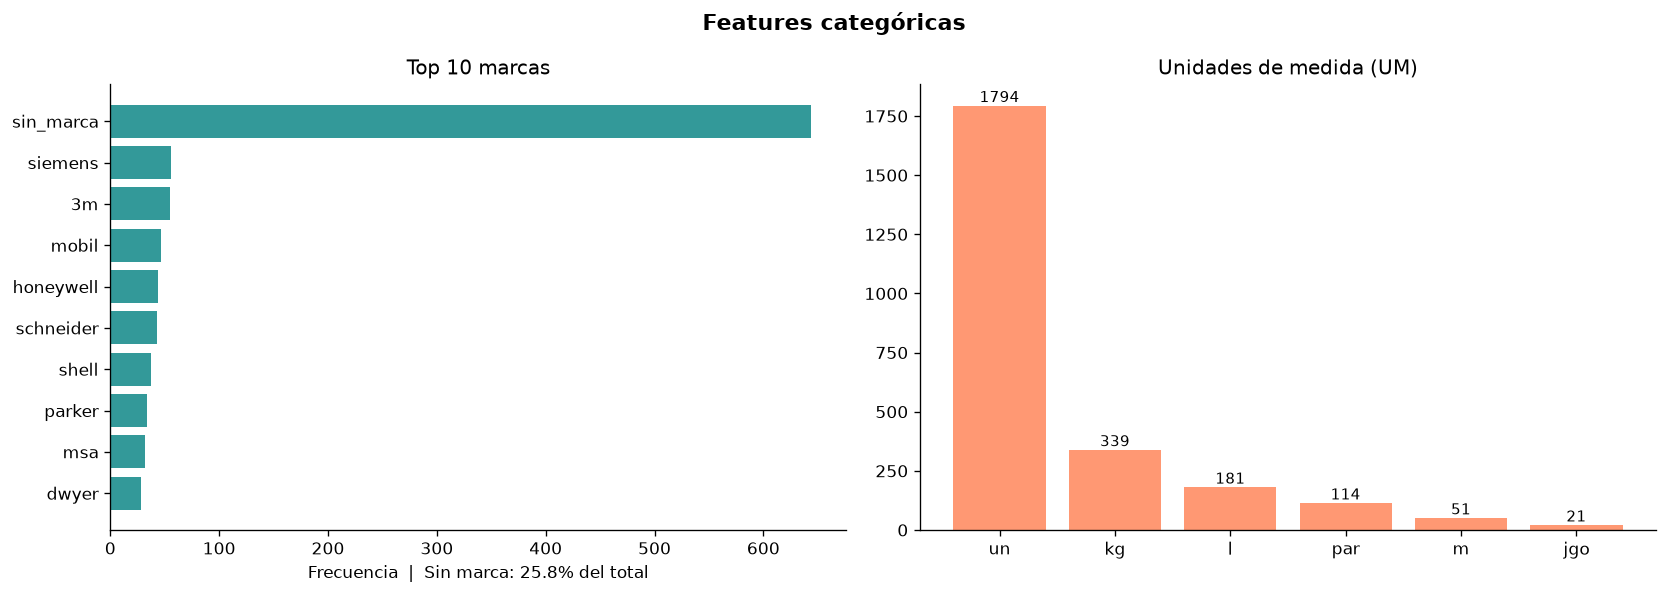

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_marcas = df['marca'].value_counts().head(10)
axes[0].barh(top_marcas.index[::-1], top_marcas.values[::-1], color='teal', alpha=0.8)
axes[0].set_title('Top 10 marcas')
pct_sm = (df['marca'] == 'sin_marca').mean() * 100
axes[0].set_xlabel(f'Frecuencia  |  Sin marca: {pct_sm:.1f}% del total')

top_um = df['um'].value_counts().head(8)
axes[1].bar(top_um.index, top_um.values, color='coral', alpha=0.8)
axes[1].set_title('Unidades de medida (UM)')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}',
                     (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha='center', va='bottom', fontsize=9)

plt.suptitle('Features categóricas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/04_features_categoricas.png', bbox_inches='tight')
plt.show()

## 4. Features Numéricas

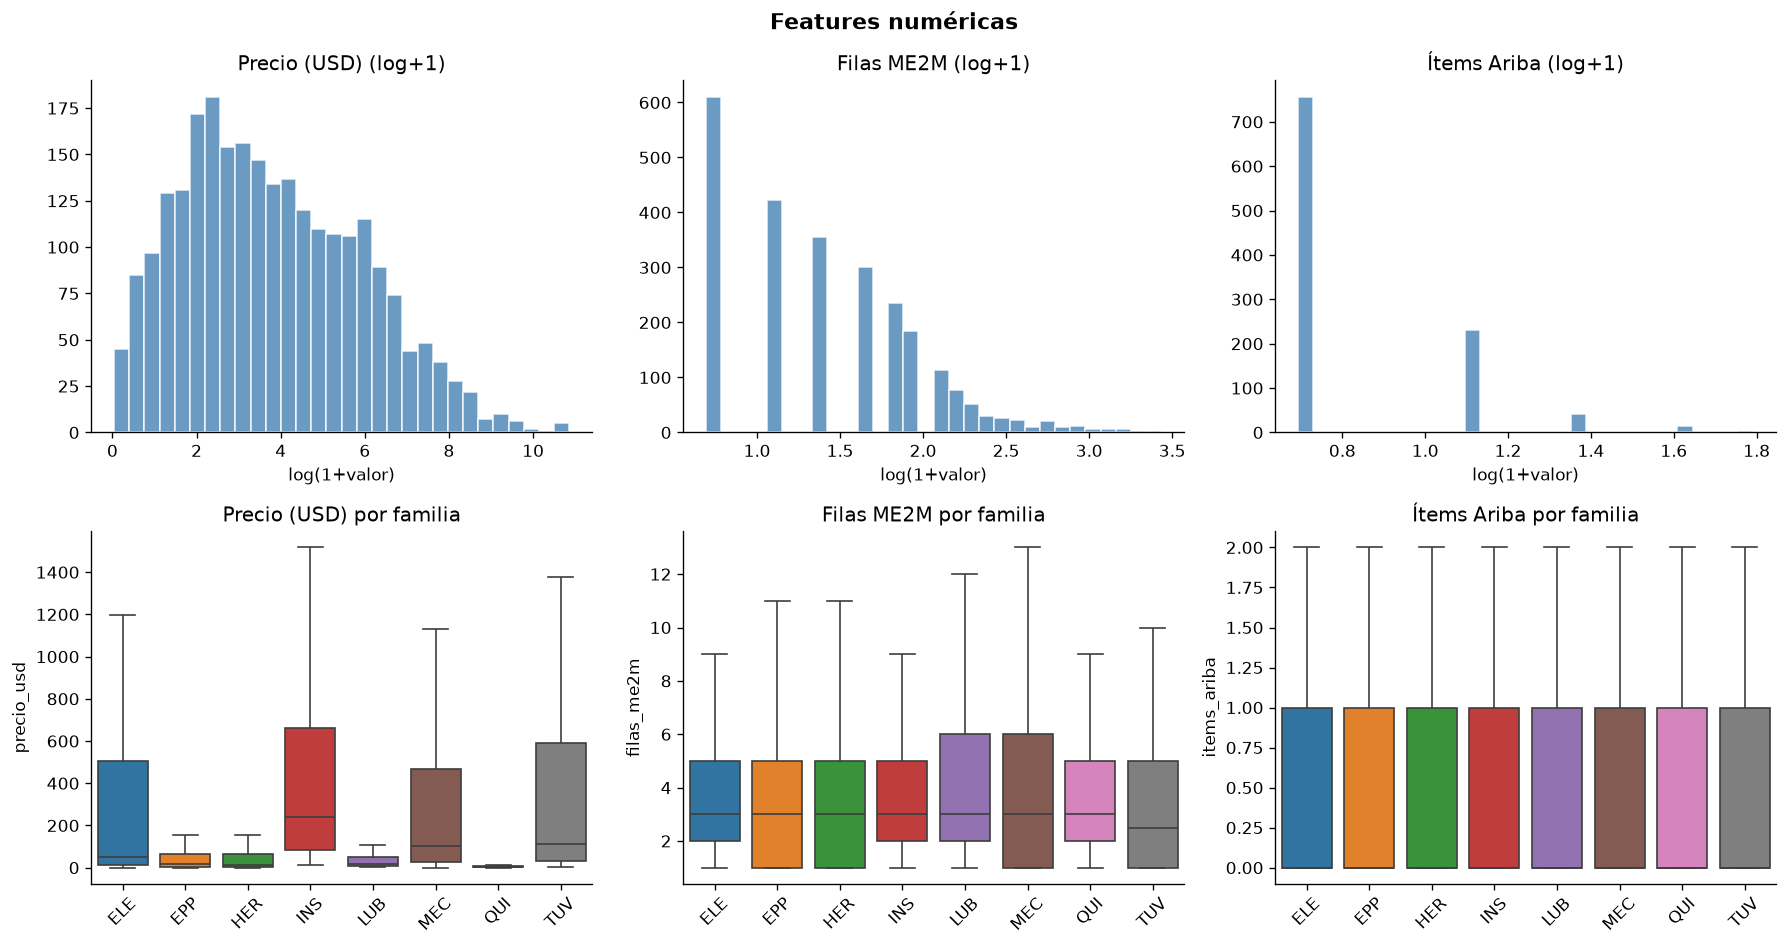

       precio_usd  filas_me2m  items_ariba
count     2500.00     2500.00      2500.00
mean       494.35        4.00         0.57
std       2628.34        3.48         0.79
min          0.04        1.00         0.00
25%          7.40        2.00         0.00
50%         32.84        3.00         0.00
75%        209.24        5.00         1.00
max      52021.04       30.00         5.00


In [14]:
numeric_cols = ['precio_usd', 'filas_me2m', 'items_ariba']
num_labels   = ['Precio (USD)', 'Filas ME2M', 'Ítems Ariba']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (col, lbl) in enumerate(zip(numeric_cols, num_labels)):
    # Fila 0: histograma en escala log
    ax = axes[0, i]
    vals = df[col][df[col] > 0]
    ax.hist(np.log1p(vals), bins=30, color='steelblue', edgecolor='white', alpha=0.8)
    ax.set_title(f'{lbl} (log+1)')
    ax.set_xlabel('log(1+valor)')
    # Fila 1: boxplot por familia
    ax2 = axes[1, i]
    sns.boxplot(data=df, x='familia_cod', y=col,
                order=sorted(df['familia_cod'].unique()),
                palette='tab10', ax=ax2, showfliers=False)
    ax2.set_title(f'{lbl} por familia')
    ax2.set_xlabel('')
    ax2.tick_params(axis='x', rotation=45)

plt.suptitle('Features numéricas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/05_features_numericas.png', bbox_inches='tight')
plt.show()
print(df[numeric_cols].describe().round(2))

## 5. Correlación

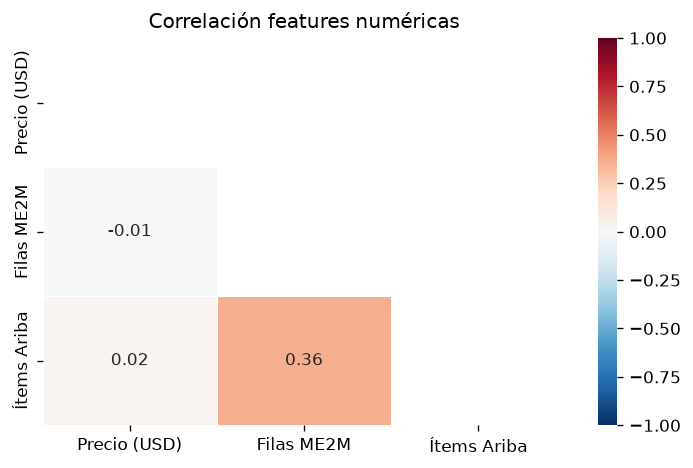

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, xticklabels=num_labels, yticklabels=num_labels,
            ax=ax, linewidths=0.5)
ax.set_title('Correlación features numéricas')
plt.tight_layout()
plt.savefig('../reports/figures/06_correlacion.png', bbox_inches='tight')
plt.show()

## 6. Conclusiones

In [16]:
ratio = df['familia_cod'].value_counts().max() / df['familia_cod'].value_counts().min()

print('=' * 58)
print('RESUMEN EDA — Clasificación de Materiales')
print('=' * 58)
print(f"""
DATASET
  Filas: {len(df):,}  |  Columnas: {df.shape[1]}  |  Nulos: 0

TARGET (familia_cod)
  Clases: {df['familia_cod'].nunique()}  |  Imbalance ratio: {ratio:.2f}x
  Mayoritaria: {df['familia_cod'].value_counts().idxmax()} ({df['familia_cod'].value_counts().max()} items)
  Minoritaria:  {df['familia_cod'].value_counts().idxmin()} ({df['familia_cod'].value_counts().min()} items)

TEXTO
  Breve:  {df['n_breve'].mean():.1f} palabras avg  →  feature principal
  Largo:  {df['n_largo'].mean():.1f} palabras avg  →  concatenar con breve

MARCA
  Sin marca: {(df['marca']=='sin_marca').sum()} materiales ({(df['marca']=='sin_marca').mean():.1%})

DECISIONES DE MODELADO
  ✓ TF-IDF ngram(1,2) sobre texto_completo como feature principal
  ✓ Encoding one-hot para marca y um
  ✓ StandardScaler para numéricas (outliers presentes)
  ✓ class_weight='balanced' por precaución
  ✓ Baseline: LogisticRegression → RandomForest → XGBoost
""")

RESUMEN EDA — Clasificación de Materiales

DATASET
  Filas: 2,500  |  Columnas: 16  |  Nulos: 0

TARGET (familia_cod)
  Clases: 8  |  Imbalance ratio: 1.38x
  Mayoritaria: LUB (359 items)
  Minoritaria:  MEC (261 items)

TEXTO
  Breve:  5.7 palabras avg  →  feature principal
  Largo:  17.2 palabras avg  →  concatenar con breve

MARCA
  Sin marca: 644 materiales (25.8%)

DECISIONES DE MODELADO
  ✓ TF-IDF ngram(1,2) sobre texto_completo como feature principal
  ✓ Encoding one-hot para marca y um
  ✓ StandardScaler para numéricas (outliers presentes)
  ✓ class_weight='balanced' por precaución
  ✓ Baseline: LogisticRegression → RandomForest → XGBoost

